In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('data.csv', encoding='unicode_escape')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [ ]:
import datetime as dt

print("Original data shape:", df.shape)


df = df.dropna(subset=['CustomerID'])

df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]


df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])


df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

print("Cleaned data shape:", df.shape)



reference_date = df['InvoiceDate'].max() + dt.timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,  # Recency
    'InvoiceNo': 'nunique',                                    # Frequency
    'TotalAmount': 'sum'                                       # Monetary
}).reset_index()

rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalAmount': 'Monetary'
}, inplace=True)

rfm.head()

Original data shape: (62551, 8)
Cleaned data shape: (37493, 9)


,CustomerID,Recency,Frequency,Monetary
0,12346.0,1,1,77183.60
1,12347.0,43,1,711.79
2,12348.0,33,1,892.80
3,12356.0,1,1,2271.62
4,12359.0,7,1,547.50


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm[['Recency', 'Frequency', 'Monetary']])


kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans.fit(rfm_scaled)

rfm['Cluster'] = kmeans.labels_

cluster_summary = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(1)

print(cluster_summary)

        Recency Frequency Monetary      
           mean      mean     mean count
Cluster                                 
0           9.1      12.7  12699.7    15
1          39.3       1.3    446.8   667
2           1.0       1.0  77183.6     1
3           8.2       2.0    888.5   428


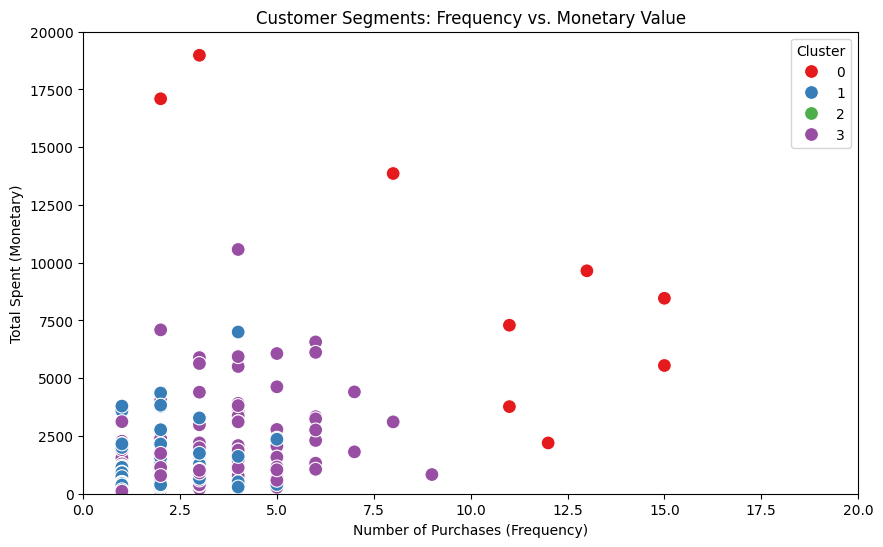

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    data=rfm,
    palette='Set1',
    s=100
)

plt.title('Customer Segments: Frequency vs. Monetary Value')
plt.xlabel('Number of Purchases (Frequency)')
plt.ylabel('Total Spent (Monetary)')

plt.xlim(0, 20)
plt.ylim(0, 20000)

plt.show()